# Lecture 7 notebook: Comparing trend systems

Companion to Lecture 7 of *Systematic Trading Notes*. The five trend families of Lecture 6, each across its parameters,
on the 16 ETFs of Lectures 5 to 9, daily, 2000–2026, sized to 10% volatility per asset and averaged with equal weights.
The notebook answers the lecture's five questions in order: at what speed (§2), does a system add anything (§3),
what do the trades show (§4), is the difference real (§5), and will it last (§6). Costs are 5 basis points per unit
traded unless stated otherwise.

In [1]:
from itertools import combinations
from pathlib import Path

import numpy as np
import pandas as pd
import plotly.graph_objects as go
from IPython.display import display
from plotly.subplots import make_subplots

from trading_models.data.ohlc import load_ohlc
from trading_models.plotting import MUTED, SERIES, apply_theme, save_figure

apply_theme()
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
RAW = ROOT / "data" / "raw"
FIG = ROOT / "lectures" / "07-comparing-trend-systems" / "figures"
TICKERS = ["SPY", "QQQ", "IWM", "EFA", "EEM", "XLE", "XLF", "XLK", "XLU", "VNQ", "AGG", "TLT", "GLD", "SLV", "GDX", "USO"]
D = load_ohlc(TICKERS, start="1993-01-01", cache=RAW / "nb05_ohlc.csv")
C, H, L = (D[f][TICKERS] for f in ("close", "high", "low"))
r = np.log(C).diff()
vol = r.ewm(span=60, min_periods=60).std()
TARGET = 0.10 / np.sqrt(252)
START = "2000-01-01"
COST = 5 / 1e4
pd.set_option("display.width", 200)

## The five families (as in Lecture 6)

Time-series momentum (the sign of the past return), price against its simple moving average, EWMAC (a continuous
forecast), the Donchian channel (entry at the N-day high or low, exit at the N/2-day opposite channel) and a
breakout with a chandelier stop (exit three average true ranges from the best price since entry).

In [2]:
def donchian(entry):
    ex = max(entry // 2, 2)
    he, le = C.rolling(entry).max().shift(1), C.rolling(entry).min().shift(1)
    hx, lx = C.rolling(ex).max().shift(1), C.rolling(ex).min().shift(1)
    out = pd.DataFrame(0.0, index=C.index, columns=C.columns)
    for t in C.columns:
        pos, ps = 0.0, []
        for px, a, b, cx, dx in zip(C[t].to_numpy(), he[t].to_numpy(), le[t].to_numpy(), hx[t].to_numpy(), lx[t].to_numpy()):
            if np.isnan(px) or np.isnan(a):
                pos = 0.0
            elif pos == 0 and px > a:
                pos = 1.0
            elif pos == 0 and px < b:
                pos = -1.0
            elif pos == 1 and px < dx:
                pos = -1.0 if px < b else 0.0
            elif pos == -1 and px > cx:
                pos = 1.0 if px > a else 0.0
            ps.append(pos)
        out[t] = ps
    return out


tr = pd.concat({t: pd.concat([H[t] - L[t], (H[t] - C[t].shift()).abs(), (L[t] - C[t].shift()).abs()], axis=1).max(axis=1) for t in TICKERS}, axis=1)
atr = tr.rolling(20).mean()


def chandelier(entry, k=3.0):
    he, le = C.rolling(entry).max().shift(1), C.rolling(entry).min().shift(1)
    out = pd.DataFrame(0.0, index=C.index, columns=C.columns)
    for t in C.columns:
        pos, ext, ps = 0.0, np.nan, []
        for px, a, b, at in zip(C[t].to_numpy(), he[t].to_numpy(), le[t].to_numpy(), atr[t].to_numpy()):
            if np.isnan(px) or np.isnan(a) or np.isnan(at):
                pos = 0.0
            elif pos == 0:
                if px > a:
                    pos, ext = 1.0, px
                elif px < b:
                    pos, ext = -1.0, px
            elif pos == 1:
                ext = max(ext, px)
                if px < ext - k * at:
                    pos = 0.0
            else:
                ext = min(ext, px)
                if px > ext + k * at:
                    pos = 0.0
            ps.append(pos)
        out[t] = ps
    return out


def ewmac(fast):
    raw = C.ewm(span=fast).mean() - C.ewm(span=4 * fast).mean()
    f = raw / (C * vol)
    f = f / f.abs().loc[START:].median().median()
    return f.clip(-2, 2)


FAMILIES = {
    "TSMOM": {n: np.sign(np.log(C).diff(n)) for n in (10, 21, 42, 63, 126, 252, 378)},
    "Price vs SMA": {n: np.sign(C - C.rolling(n).mean()) for n in (10, 20, 50, 100, 200, 300)},
    "EWMAC": {n: ewmac(n) for n in (2, 4, 8, 16, 32, 64)},
    "Donchian": {n: donchian(n) for n in (10, 20, 40, 55, 100, 200)},
    "Chandelier": {n: chandelier(n) for n in (10, 20, 40, 55, 100, 200)},
}
FAM_COL = {f: SERIES[j] for j, f in enumerate(FAMILIES)}

V = {}          # (family, parameter) -> dict of series
for fam, d in FAMILIES.items():
    for n, sig in d.items():
        pos = (sig * TARGET / vol).loc[START:]
        gross_a = pos.shift(1) * r.loc[START:]                     # per asset
        to_a = pos.diff().abs()
        port = gross_a.mean(axis=1)
        to = to_a.mean(axis=1)
        V[(fam, n)] = dict(sig=sig.loc[START:], pos=pos, gross_a=gross_a, port=port, to=to, net=port - to * COST)
print(len(V), "systems")

31 systems


## 2. A fair axis for speed (Table 2.1, chart F.1, chart F.2)

Three measures of speed for every system: changes of direction per asset per year; the average holding period,
from turnover (twice the average absolute position divided by the average daily change of position); and the trend
signature of Levine and Pedersen (2016), estimated here by regressing each system's signal on past returns over five
horizon buckets and summarising the weights by their average horizon.

In [3]:
BUCKETS = [(1, 5), (6, 21), (22, 63), (64, 126), (127, 252)]
past = {b: np.log(C).shift(b[0] - 1) - np.log(C).shift(b[1]) for b in BUCKETS}     # return over each past horizon
past = {b: (x / (vol * np.sqrt(b[1] - b[0] + 1))).loc[START:] for b, x in past.items()}


def signature(sig):
    X = np.column_stack([past[b].stack().reindex(sig.stack().index).values for b in BUCKETS])
    y = sig.stack().values
    ok = np.isfinite(X).all(axis=1) & np.isfinite(y)
    beta = np.linalg.lstsq(X[ok], y[ok], rcond=None)[0]
    w = np.clip(beta, 0, None); w = w / w.sum() if w.sum() > 0 else w
    mid = np.array([(a + b) / 2 for a, b in BUCKETS])
    return w, float((w * mid).sum())


def sharpe(x):
    return np.sqrt(252) * x.mean() / x.std()


rows = []
for (fam, n), v in V.items():
    s = np.sign(v["sig"]).fillna(0)
    changes = float(((s.diff().abs() > 0).sum() / 26.5).median())
    hold = float((2 * v["pos"].abs().mean() / v["pos"].diff().abs().mean()).median())
    w, avg_lag = signature(v["sig"])
    v["sigw"] = w
    rows.append(dict(family=fam, parameter=n, changes_per_year=changes, holding_days=hold, signature_lag_days=avg_lag,
                     turnover_per_year=252 * v["to"].mean(), sharpe_gross=sharpe(v["port"]), sharpe_net=sharpe(v["net"])))
T2 = pd.DataFrame(rows)
display(T2.round(2))

,family,parameter,changes_per_year,holding_days,signature_lag_days,turnover_per_year,sharpe_gross,sharpe_net
0,TSMOM,10,33.09,6.83,10.19,49.42,-0.07,-0.54
1,TSMOM,21,22.34,9.91,10.14,33.51,0.20,-0.12
2,TSMOM,42,15.58,14.05,22.02,24.14,0.41,0.18
3,TSMOM,63,11.83,17.21,27.65,19.25,0.28,0.10
4,TSMOM,126,7.70,23.38,56.02,13.82,0.51,0.38
5,TSMOM,252,5.30,33.01,102.31,9.88,0.56,0.47
6,TSMOM,378,3.92,36.35,102.27,7.94,0.41,0.34
7,Price vs SMA,10,42.02,5.44,9.85,62.22,-0.13,-0.70
8,Price vs SMA,20,27.92,7.94,10.54,41.93,0.13,-0.27
9,Price vs SMA,50,16.49,12.61,16.72,25.86,0.19,-0.06


In [4]:
# how much the gap between families depends on the axis: interpolate each family's net Sharpe ratio at common speeds
def gap_on(axis, points):
    out = []
    for x in points:
        vals = []
        for fam, g in T2.groupby("family"):
            g = g.sort_values(axis)
            if g[axis].min() <= x <= g[axis].max():
                vals.append(np.interp(np.log(x), np.log(g[axis]), g["sharpe_net"]))
        if len(vals) >= 4:
            out.append(max(vals) - min(vals))
    return np.mean(out) if out else np.nan

axes = {"changes_per_year": np.geomspace(2, 12, 6), "holding_days": np.geomspace(15, 80, 6), "signature_lag_days": np.geomspace(20, 90, 6)}
display(pd.Series({a: gap_on(a, p) for a, p in axes.items()}, name="average gap between best and worst family at equal speed").round(2))

changes_per_year      0.32
holding_days          0.28
signature_lag_days    0.09
Name: average gap between best and worst family at equal speed, dtype: float64

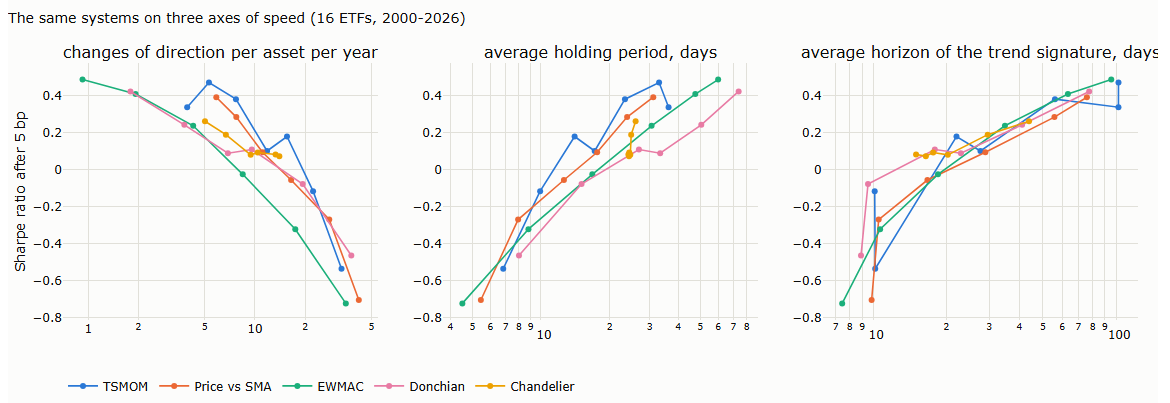

In [5]:
lab = {"changes_per_year": "changes of direction per asset per year", "holding_days": "average holding period, days",
       "signature_lag_days": "average horizon of the trend signature, days"}
fig = make_subplots(rows=1, cols=3, subplot_titles=[lab[a] for a in lab], horizontal_spacing=0.06)
for j, a in enumerate(lab):
    for fam, g in T2.groupby("family", sort=False):
        g = g.sort_values(a)
        fig.add_scatter(x=g[a], y=g["sharpe_net"], mode="lines+markers", name=fam, line=dict(color=FAM_COL[fam], width=1.6),
                        showlegend=(j == 0), row=1, col=j + 1)
    fig.update_xaxes(type="log", row=1, col=j + 1)
fig.update_yaxes(title_text="Sharpe ratio after 5 bp", row=1, col=1)
fig.update_layout(title="The same systems on three axes of speed (16 ETFs, 2000-2026)", height=430, width=1150, margin=dict(t=80),
                  legend=dict(orientation="h", y=-0.2, x=0))
save_figure(fig, "07_01_three_axes", FIG)
fig

target holding period, days: 24.2
matched systems: {'TSMOM': 126, 'Price vs SMA': 200, 'EWMAC': 16, 'Donchian': 40, 'Chandelier': 20}


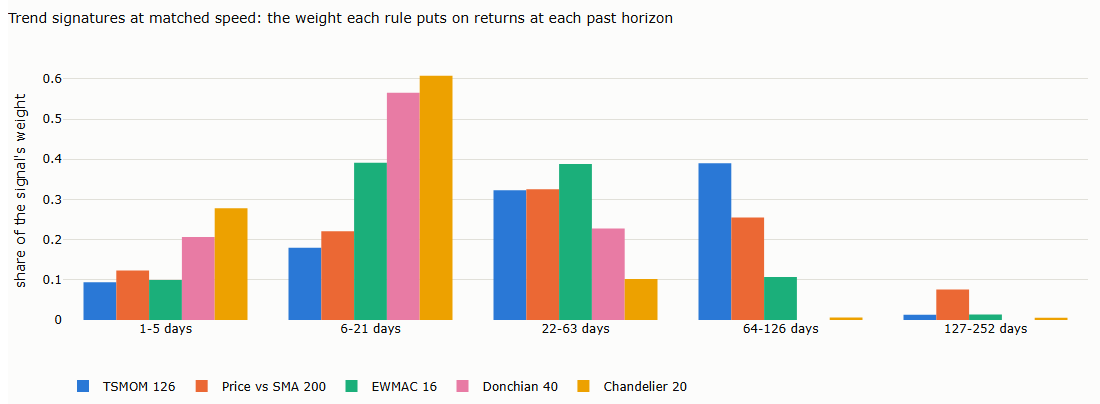

In [6]:
# matched speed: for each family, the parameter whose holding period is closest to the median of all systems
target_hold = T2.holding_days.median()
MATCH = {fam: g.iloc[(np.log(g.holding_days) - np.log(target_hold)).abs().argmin()].parameter for fam, g in T2.groupby("family", sort=False)}
MATCH = {f: (int(p) if float(p).is_integer() else p) for f, p in MATCH.items()}
print("target holding period, days:", round(target_hold, 1)); print("matched systems:", MATCH)
fig = go.Figure()
names = [f"{a}-{b} days" for a, b in BUCKETS]
for fam, n in MATCH.items():
    fig.add_bar(x=names, y=V[(fam, n)]["sigw"], name=f"{fam} {n}", marker_color=FAM_COL[fam])
fig.update_layout(barmode="group", title="Trend signatures at matched speed: the weight each rule puts on returns at each past horizon",
                  yaxis_title="share of the signal's weight", height=430, width=1100, margin=dict(t=80), legend=dict(orientation="h", y=-0.2, x=0))
save_figure(fig, "07_02_signatures", FIG)
fig

## 3. Does a system add anything? (Table 3.1, chart F.3, chart F.4)

Correlations at matched speed; the spanning regression of each family on the other four (monthly returns, Newey–West
standard errors); and the breakeven cost, the cost per unit traded at which the Sharpe ratio falls to zero.

In [7]:
M = pd.DataFrame({f: V[(f, n)]["net"] for f, n in MATCH.items()})
corr = M.corr()
display(corr.round(2))
mon = (1 + M).resample("ME").prod() - 1


def ols_nw(y, X, lags=6):
    d = pd.concat([y, X], axis=1).dropna(); yv = d.iloc[:, 0].values; Xv = np.column_stack([np.ones(len(d)), d.iloc[:, 1:].values])
    b = np.linalg.lstsq(Xv, yv, rcond=None)[0]; e = yv - Xv @ b
    XtXi = np.linalg.inv(Xv.T @ Xv); u = Xv * e[:, None]; S = u.T @ u
    for l in range(1, lags + 1):
        G = u[l:].T @ u[:-l]; S += (1 - l / (lags + 1)) * (G + G.T)
    V_ = XtXi @ S @ XtXi
    return b[0], b[0] / np.sqrt(V_[0, 0]), 1 - e.var() / yv.var()


span = {}
for f in M:
    a, t, r2 = ols_nw(mon[f], mon.drop(columns=f))
    span[f] = {"alpha % a year": 1200 * a, "t-statistic": t, "R squared": r2, "Sharpe alone": sharpe(M[f])}
T3 = pd.DataFrame(span).T
display(T3.round(2))
T2["breakeven_bp"] = [1e4 * V[(f, p)]["port"].mean() / V[(f, p)]["to"].mean() for f, p in zip(T2.family, T2.parameter)]
display(T2[["family", "parameter", "holding_days", "breakeven_bp"]].round(1))

,TSMOM,Price vs SMA,EWMAC,Donchian,Chandelier
TSMOM,1.00,0.91,0.79,0.56,0.48
Price vs SMA,0.91,1.00,0.85,0.65,0.56
EWMAC,0.79,0.85,1.00,0.86,0.75
Donchian,0.56,0.65,0.86,1.00,0.92
Chandelier,0.48,0.56,0.75,0.92,1.00


,alpha % a year,t-statistic,R squared,Sharpe alone
TSMOM,0.71,1.89,0.78,0.38
Price vs SMA,-0.24,-0.68,0.86,0.28
EWMAC,0.20,0.54,0.91,0.24
Donchian,-0.12,-0.48,0.90,0.11
Chandelier,-0.05,-0.14,0.82,0.08


,family,parameter,holding_days,breakeven_bp
0,TSMOM,10,6.8,-0.8
1,TSMOM,21,9.9,3.1
2,TSMOM,42,14.0,8.9
3,TSMOM,63,17.2,7.8
4,TSMOM,126,23.4,19.9
5,TSMOM,252,33.0,31.3
6,TSMOM,378,36.3,29.1
7,Price vs SMA,10,5.4,-1.1
8,Price vs SMA,20,7.9,1.6
9,Price vs SMA,50,12.6,3.9


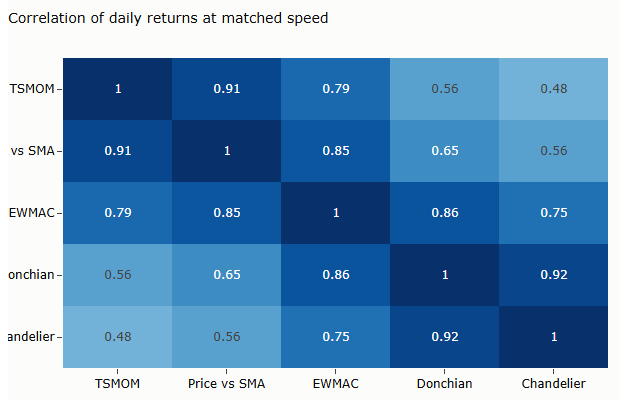

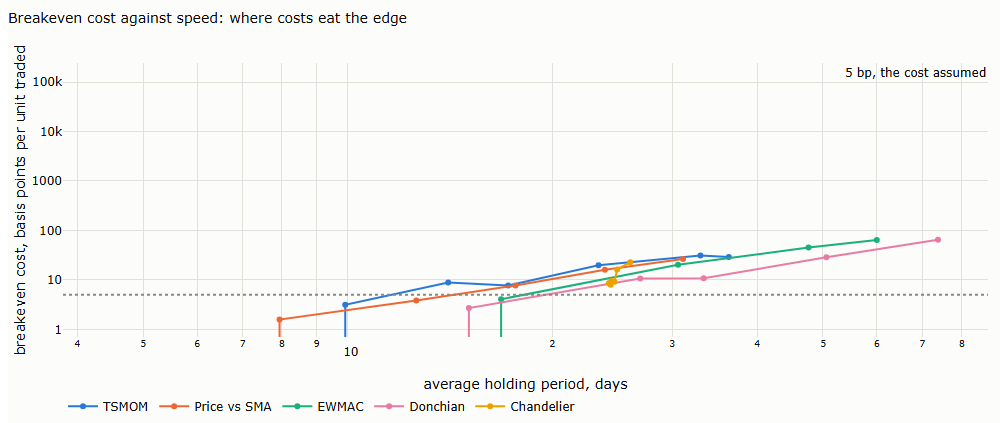

In [8]:
fig = go.Figure(go.Heatmap(z=corr.values, x=list(corr.columns), y=list(corr.index), zmin=0, zmax=1, colorscale="Blues",
                           text=corr.round(2).values, texttemplate="%{text}", showscale=False))
fig.update_layout(title="Correlation of daily returns at matched speed", height=420, width=620, margin=dict(t=70), yaxis=dict(autorange="reversed"))
save_figure(fig, "07_03_correlations", FIG)
display(fig)
fig = go.Figure()
for fam, g in T2.groupby("family", sort=False):
    g = g.sort_values("holding_days")
    fig.add_scatter(x=g.holding_days, y=g.breakeven_bp, mode="lines+markers", name=fam, line=dict(color=FAM_COL[fam]))
fig.add_hline(y=5, line=dict(color=MUTED, dash="dot"), annotation_text="5 bp, the cost assumed")
fig.update_layout(title="Breakeven cost against speed: where costs eat the edge", xaxis=dict(title="average holding period, days", type="log"),
                  yaxis=dict(title="breakeven cost, basis points per unit traded", type="log"), height=450, width=1000, margin=dict(t=80),
                  legend=dict(orientation="h", y=-0.2, x=0))
save_figure(fig, "07_04_breakeven", FIG)
fig

## 4. Trades, sides and time in the market (Tables 4.1–4.3, charts F.5–F.7)

A trade is a spell of one asset in one direction, from the day the position takes a sign to the day it changes;
its return is the sum of the daily returns of that position, in units of the 10% risk target. Shown at matched speed.

In [9]:
def trades(v):
    out = []
    for t in TICKERS:
        s = np.sign(v["pos"][t]).fillna(0).values
        g = v["gross_a"][t].fillna(0).values
        start, cur = None, 0
        for i in range(len(s)):
            if s[i] != cur:
                if cur != 0 and start is not None:
                    out.append((t, cur, i - start, g[start + 1:i + 1].sum()))
                cur, start = s[i], i
        if cur != 0 and start is not None:
            out.append((t, cur, len(s) - start, g[start + 1:].sum()))
    return pd.DataFrame(out, columns=["asset", "side", "days", "ret"])


TR = {f: trades(V[(f, n)]) for f, n in MATCH.items()}
rows = {}
for f, x in TR.items():
    win, loss = x.ret[x.ret > 0], x.ret[x.ret < 0]
    top = x.ret.sort_values(ascending=False)
    rows[f] = {"trades per asset per year": len(x) / 16 / 26.5, "average days held": x.days.mean(), "win rate %": 100 * (x.ret > 0).mean(),
               "average win / average loss": win.mean() / -loss.mean(), "skewness of trade returns": x.ret.skew(),
               "share of profit from best tenth %": 100 * top.iloc[:max(len(top) // 10, 1)].sum() / x.ret.sum()}
T41 = pd.DataFrame(rows).T
display(T41.round(2))

,trades per asset per year,average days held,win rate %,average win / average loss,skewness of trade returns,share of profit from best tenth %
TSMOM,7.95,28.61,31.56,3.14,5.37,282.18
Price vs SMA,7.79,29.00,14.09,8.42,5.87,356.09
EWMAC,4.15,55.24,18.43,6.14,4.12,315.34
Donchian,4.97,33.91,37.59,1.93,2.29,454.17
Chandelier,6.61,29.21,37.80,1.84,2.04,587.62


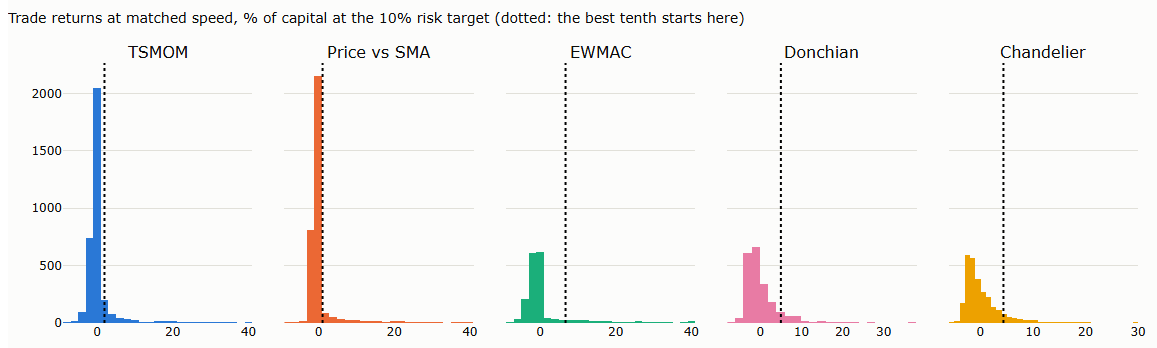

In [10]:
fig = make_subplots(rows=1, cols=5, subplot_titles=list(TR), shared_yaxes=True, horizontal_spacing=0.03)
for j, (f, x) in enumerate(TR.items()):
    rr = 100 * x.ret.clip(-0.15, 0.4)
    cut = 100 * x.ret.sort_values(ascending=False).iloc[len(x) // 10]
    fig.add_histogram(x=rr, nbinsx=40, marker_color=FAM_COL[f], showlegend=False, row=1, col=j + 1)
    fig.add_vline(x=cut, line=dict(color="black", dash="dot"), row=1, col=j + 1)
fig.update_layout(title="Trade returns at matched speed, % of capital at the 10% risk target (dotted: the best tenth starts here)",
                  height=380, width=1150, margin=dict(t=80))
save_figure(fig, "07_05_trade_returns", FIG)
fig

,"long side, % a year","short side, % a year",Sharpe long side,Sharpe short side
TSMOM,3.06,-0.53,0.72,-0.17
Price vs SMA,2.78,-0.76,0.66,-0.24
EWMAC,3.00,-0.81,0.54,-0.19
Donchian,1.89,-0.92,0.61,-0.29
Chandelier,1.86,-0.97,0.56,-0.29


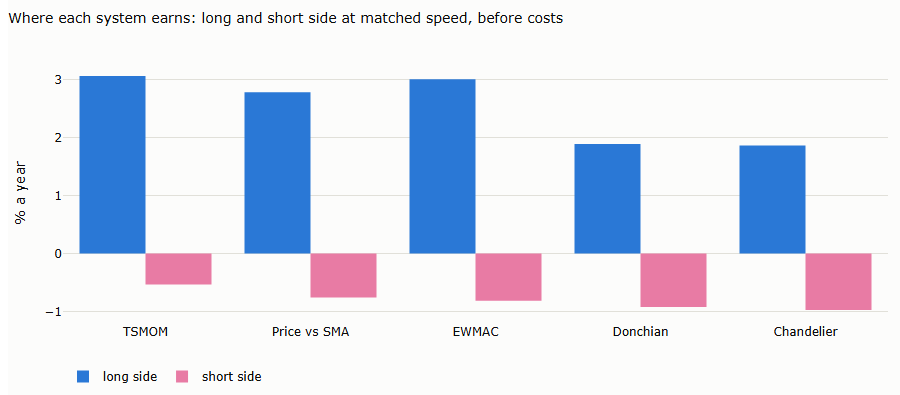

In [11]:
side = {}
for f, n in MATCH.items():
    v = V[(f, n)]; lng = (v["gross_a"].where(v["pos"].shift(1) > 0, 0)).mean(axis=1); sht = (v["gross_a"].where(v["pos"].shift(1) < 0, 0)).mean(axis=1)
    side[f] = {"long side, % a year": 100 * 252 * lng.mean(), "short side, % a year": 100 * 252 * sht.mean(),
               "Sharpe long side": sharpe(lng), "Sharpe short side": sharpe(sht)}
T42 = pd.DataFrame(side).T
display(T42.round(2))
fig = go.Figure()
fig.add_bar(x=T42.index, y=T42["long side, % a year"], name="long side", marker_color=SERIES[0])
fig.add_bar(x=T42.index, y=T42["short side, % a year"], name="short side", marker_color=SERIES[3])
fig.update_layout(barmode="group", title="Where each system earns: long and short side at matched speed, before costs", yaxis_title="% a year",
                  height=420, width=900, margin=dict(t=80), legend=dict(orientation="h", y=-0.15, x=0))
save_figure(fig, "07_06_sides", FIG)
fig

,family,parameter,time_in_market,sharpe_asset_whole,sharpe_asset_invested
19,Donchian,10,0.67,-0.06,-0.08
20,Donchian,20,0.68,0.06,0.06
21,Donchian,40,0.68,0.10,0.11
22,Donchian,55,0.67,0.06,0.08
23,Donchian,100,0.67,0.15,0.19
24,Donchian,200,0.68,0.24,0.32
25,Chandelier,10,0.81,0.09,0.10
26,Chandelier,20,0.75,0.09,0.10
27,Chandelier,40,0.61,0.05,0.06
28,Chandelier,55,0.55,0.07,0.10


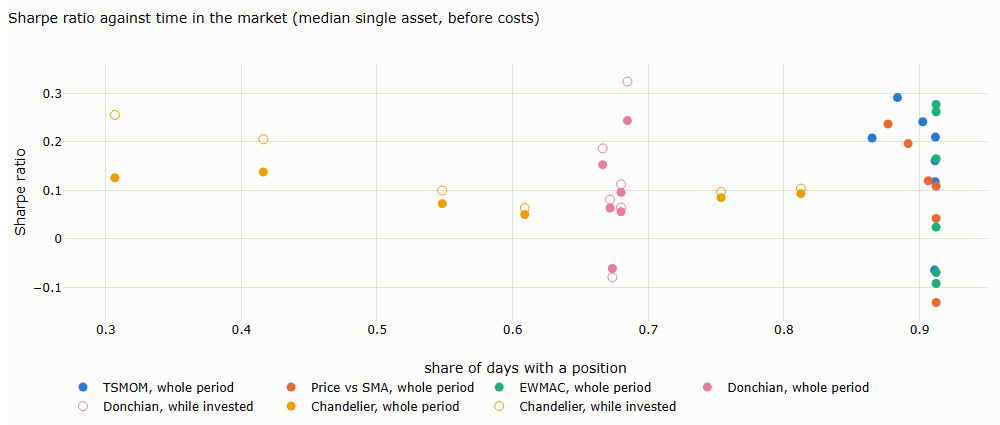

In [12]:
# time in the market, and the Sharpe ratio while invested (per asset, median across assets)
rows = []
for (f, n), v in V.items():
    inv = v["pos"].shift(1).abs() > 0
    p = float(inv.mean().median())
    sw = np.nanmedian([sharpe(v["gross_a"][t][inv[t]]) for t in TICKERS])
    sa = np.nanmedian([sharpe(v["gross_a"][t].fillna(0)) for t in TICKERS])
    rows.append(dict(family=f, parameter=n, time_in_market=p, sharpe_asset_whole=sa, sharpe_asset_invested=sw))
T43 = pd.DataFrame(rows)
display(T43[T43.family.isin(["Donchian", "Chandelier"])].round(2))
fig = go.Figure()
for fam, g in T43.groupby("family", sort=False):
    fig.add_scatter(x=g.time_in_market, y=g.sharpe_asset_whole, mode="markers", name=f"{fam}, whole period", marker=dict(color=FAM_COL[fam], size=9))
    if fam in ("Donchian", "Chandelier"):
        fig.add_scatter(x=g.time_in_market, y=g.sharpe_asset_invested, mode="markers", name=f"{fam}, while invested",
                        marker=dict(color=FAM_COL[fam], size=9, symbol="circle-open"))
fig.update_layout(title="Sharpe ratio against time in the market (median single asset, before costs)", xaxis_title="share of days with a position",
                  yaxis_title="Sharpe ratio", height=450, width=1000, margin=dict(t=80), legend=dict(orientation="h", y=-0.2, x=0))
save_figure(fig, "07_07_time_in_market", FIG)
fig

In [13]:
# marginal contribution of the system that is often flat: Chandelier on EWMAC at matched speed, flat days earning zero
a, t, r2 = ols_nw(mon["Chandelier"], mon[["EWMAC"]])
print(f"Chandelier on EWMAC: alpha {1200 * a:.2f}% a year, t {t:.2f}, R squared {r2:.2f}")

Chandelier on EWMAC: alpha -0.49% a year, t -1.02, R squared 0.59


## 4.5 Beyond the Sharpe ratio: Omega and drawdowns (Table 4.4, chart F.8)

The Omega ratio at a threshold of zero is the sum of gains divided by the sum of losses: it uses the whole
distribution of returns rather than its variance. Drawdowns measure what running a system feels like: how deep,
how long, and whether two systems lose at the same time.

,Sharpe,"Omega, daily","Omega, monthly",maximum drawdown %,average drawdown %,"longest under water, years"
TSMOM,0.38,1.07,1.36,-18.46,-6.50,3.25
Price vs SMA,0.28,1.05,1.25,-18.03,-7.29,3.26
EWMAC,0.24,1.04,1.21,-22.90,-7.80,5.10
Donchian,0.11,1.02,1.09,-21.18,-8.50,6.66
Chandelier,0.08,1.01,1.06,-25.05,-9.46,6.71


correlation of drawdown paths  share of days both more than 10% under water
TSMOM        Price vs SMA                           0.80                                          0.17
             EWMAC                                  0.66                                          0.15
             Donchian                               0.33                                          0.11
             Chandelier                             0.31                                          0.14
Price vs SMA EWMAC                                  0.70                                          0.19
             Donchian                               0.50                                          0.17
             Chandelier                             0.43                                          0.21
EWMAC        Donchian                               0.80                                          0.23
             Chandelier                             0.79                                          0.25
Donchian     Chandelier                             0.83                                          0.30

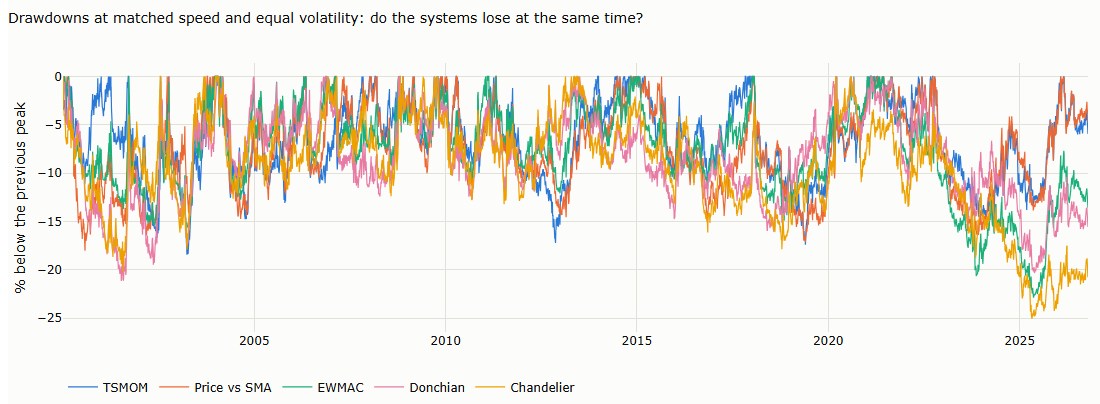

In [14]:
def omega(x, thr=0.0):
    d = x - thr
    return d[d > 0].sum() / -d[d < 0].sum()


def drawdown(x):
    w = (1 + x).cumprod(); return w / w.cummax() - 1


def longest_under_water(dd):
    best = cur = 0
    for u in (dd < 0).values:
        cur = cur + 1 if u else 0; best = max(best, cur)
    return best / 252


rows = {}
DD = {}
for f in M:
    x = M[f] / M[f].std() * TARGET                                    # same 10% volatility for all
    dd = drawdown(x); DD[f] = dd
    m = (1 + x).resample("ME").prod() - 1
    rows[f] = {"Sharpe": sharpe(x), "Omega, daily": omega(x), "Omega, monthly": omega(m), "maximum drawdown %": 100 * dd.min(),
               "average drawdown %": 100 * dd.mean(), "longest under water, years": longest_under_water(dd)}
T44 = pd.DataFrame(rows).T
display(T44.round(2))
DDf = pd.DataFrame(DD)
both = pd.DataFrame({(a, b): ((DDf[a] < -0.10) & (DDf[b] < -0.10)).mean() for a, b in combinations(DDf.columns, 2)}, index=["share of days both more than 10% under water"]).T
display(pd.concat([DDf.corr().stack().rename("correlation of drawdown paths"), both.iloc[:, 0]], axis=1).dropna().round(2))
fig = go.Figure()
for f in DDf:
    fig.add_scatter(x=DDf.index, y=100 * DDf[f], name=f, line=dict(color=FAM_COL[f], width=1.2))
fig.update_layout(title="Drawdowns at matched speed and equal volatility: do the systems lose at the same time?", yaxis_title="% below the previous peak",
                  height=430, width=1100, margin=dict(t=80), legend=dict(orientation="h", y=-0.15, x=0))
save_figure(fig, "07_08_drawdowns", FIG)
fig

## 5. Is the difference real? (Table 5.1, Table 5.2, charts F.9, F.10)

Block-bootstrap bands: resample 21-day blocks of days, the same blocks for every system so that their correlation
is kept, and recompute every curve 500 times. A bootstrap test of the Sharpe-ratio difference for pairs at equal
speed, in the spirit of Ledoit and Wolf (2008). The probability of backtest overfitting (Bailey et al., 2017) by
combinatorially symmetric cross-validation: 16 blocks of time, every split into 8 and 8.

average width of the 90% band: 0.56


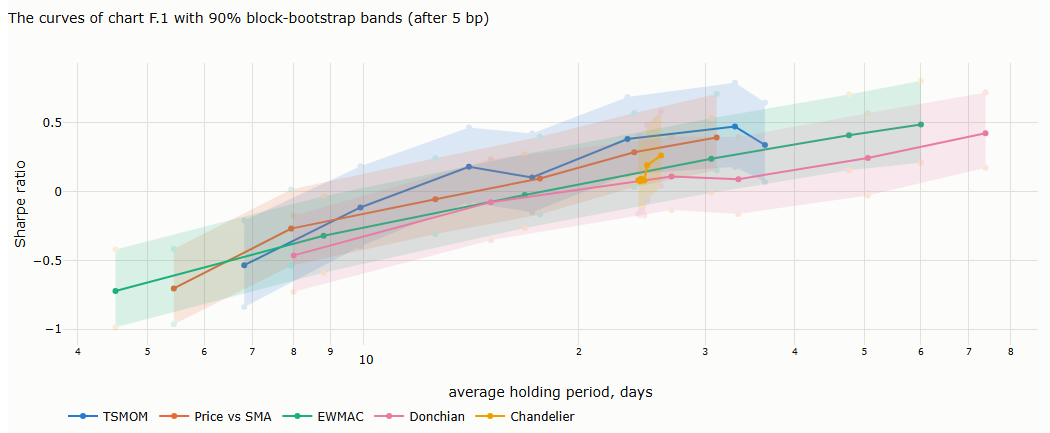

In [15]:
NET = pd.DataFrame({k: v["net"] for k, v in V.items()}).dropna()
X = NET.values
rng = np.random.default_rng(7)
B, BL = 500, 21
nb = int(np.ceil(len(X) / BL))
boots = np.empty((B, X.shape[1]))
for b in range(B):
    starts = rng.integers(0, len(X) - BL, nb)
    idx_ = (starts[:, None] + np.arange(BL)).ravel()[:len(X)]
    xb = X[idx_]
    boots[b] = np.sqrt(252) * xb.mean(0) / xb.std(0)
band = pd.DataFrame({"low": np.percentile(boots, 5, 0), "high": np.percentile(boots, 95, 0)}, index=NET.columns)
print("average width of the 90% band:", round(float((band.high - band.low).mean()), 2))
fig = go.Figure()
for fam, g in T2.groupby("family", sort=False):
    g = g.sort_values("holding_days"); keys = list(zip(g.family, g.parameter))
    lo, hi = band.loc[keys, "low"].values, band.loc[keys, "high"].values
    fig.add_scatter(x=list(g.holding_days) + list(g.holding_days[::-1]), y=list(hi) + list(lo[::-1]), fill="toself", line=dict(width=0),
                    fillcolor=FAM_COL[fam], opacity=0.15, showlegend=False, hoverinfo="skip")
    fig.add_scatter(x=g.holding_days, y=g.sharpe_net, mode="lines+markers", name=fam, line=dict(color=FAM_COL[fam]))
fig.update_layout(title="The curves of chart F.1 with 90% block-bootstrap bands (after 5 bp)", xaxis=dict(title="average holding period, days", type="log"),
                  yaxis_title="Sharpe ratio", height=460, width=1050, margin=dict(t=80), legend=dict(orientation="h", y=-0.2, x=0))
save_figure(fig, "07_09_bootstrap_bands", FIG)
fig

In [16]:
# test of a Sharpe-ratio difference at equal speed, by block bootstrap of the difference
def sharpe_diff_test(a, b, B=2000, BL=21, seed=11):
    d = pd.concat([a, b], axis=1).dropna().values; n = len(d); rng = np.random.default_rng(seed)
    obs = np.sqrt(252) * (d[:, 0].mean() / d[:, 0].std() - d[:, 1].mean() / d[:, 1].std())
    k = int(np.ceil(n / BL)); diffs = np.empty(B)
    for i in range(B):
        ix = (rng.integers(0, n - BL, k)[:, None] + np.arange(BL)).ravel()[:n]; x = d[ix]
        diffs[i] = np.sqrt(252) * (x[:, 0].mean() / x[:, 0].std() - x[:, 1].mean() / x[:, 1].std())
    p = 2 * min((diffs - obs <= -abs(obs)).mean() + (diffs - obs >= abs(obs)).mean(), 0.5) if False else 2 * min((diffs <= 0).mean(), (diffs >= 0).mean())
    return obs, np.percentile(diffs, 5), np.percentile(diffs, 95), p


pairs = [("EWMAC", "TSMOM"), ("EWMAC", "Price vs SMA"), ("Donchian", "Chandelier"), ("EWMAC", "Donchian"), ("TSMOM", "Price vs SMA")]
T51 = pd.DataFrame({f"{a} vs {b}": dict(zip(["difference", "5%", "95%", "p-value"], sharpe_diff_test(V[(a, MATCH[a])]["net"], V[(b, MATCH[b])]["net"])))
                    for a, b in pairs}).T
display(T51.round(2))

,difference,5%,95%,p-value
EWMAC vs TSMOM,-0.14,-0.33,0.04,0.21
EWMAC vs Price vs SMA,-0.05,-0.20,0.12,0.68
Donchian vs Chandelier,0.03,-0.10,0.15,0.77
EWMAC vs Donchian,0.13,-0.01,0.27,0.14
TSMOM vs Price vs SMA,0.10,-0.04,0.24,0.23


In [17]:
# probability of backtest overfitting by combinatorially symmetric cross-validation (16 blocks of time)
def pbo(R, S=16):
    n = len(R) // S * S; blocks = np.array_split(np.arange(n), S); Rv = R.values[:n]
    mu = np.array([Rv[b].mean(0) for b in blocks]); sd = np.array([Rv[b].std(0) for b in blocks])
    sums, sq, cnt = mu * np.array([len(b) for b in blocks])[:, None], None, None
    logits, perf_oos, perf_is = [], [], []
    lens = np.array([len(b) for b in blocks])[:, None]
    m2 = np.array([(Rv[b] ** 2).mean(0) for b in blocks])
    for c in combinations(range(S), S // 2):
        i = np.zeros(S, bool); i[list(c)] = True
        def sr(mask):
            w = lens[mask]; m = (mu[mask] * w).sum(0) / w.sum(); v = (m2[mask] * w).sum(0) / w.sum() - m ** 2
            return m / np.sqrt(v)
        is_, oos = sr(i), sr(~i)
        best = is_.argmax()
        rank = (oos < oos[best]).mean() + 0.5 / len(oos)           # relative rank out of sample, in (0, 1)
        logits.append(np.log(rank / (1 - rank))); perf_is.append(is_[best]); perf_oos.append(oos[best])
    logits = np.array(logits)
    return (logits <= 0).mean(), np.sqrt(252) * np.median(perf_oos), np.sqrt(252) * np.median(perf_is)


rows = {}
for fam in FAMILIES:
    cols = [k for k in NET.columns if k[0] == fam]
    rows[fam] = dict(zip(["probability of overfitting", "best in sample, median Sharpe out of sample", "best in sample, median Sharpe in sample"], pbo(NET[cols])))
rows["all 31 systems"] = dict(zip(["probability of overfitting", "best in sample, median Sharpe out of sample", "best in sample, median Sharpe in sample"], pbo(NET)))
T52 = pd.DataFrame(rows).T
display(T52.round(2))

,probability of overfitting,"best in sample, median Sharpe out of sample","best in sample, median Sharpe in sample"
TSMOM,0.15,0.36,0.51
Price vs SMA,0.00,0.36,0.40
EWMAC,0.00,0.46,0.50
Donchian,0.01,0.42,0.42
Chandelier,0.08,0.23,0.27
all 31 systems,0.07,0.37,0.53


,"rank correlation, half A against half B",Sharpe on B of the best on A,median Sharpe on B,best on B
family,,,,
Chandelier,0.20,0.25,0.21,0.25
Donchian,0.83,0.30,0.19,0.30
EWMAC,1.00,0.31,0.13,0.31
Price vs SMA,0.94,0.29,0.11,0.29
TSMOM,0.89,0.32,0.17,0.32


rank correlation across all 31 systems: 0.87


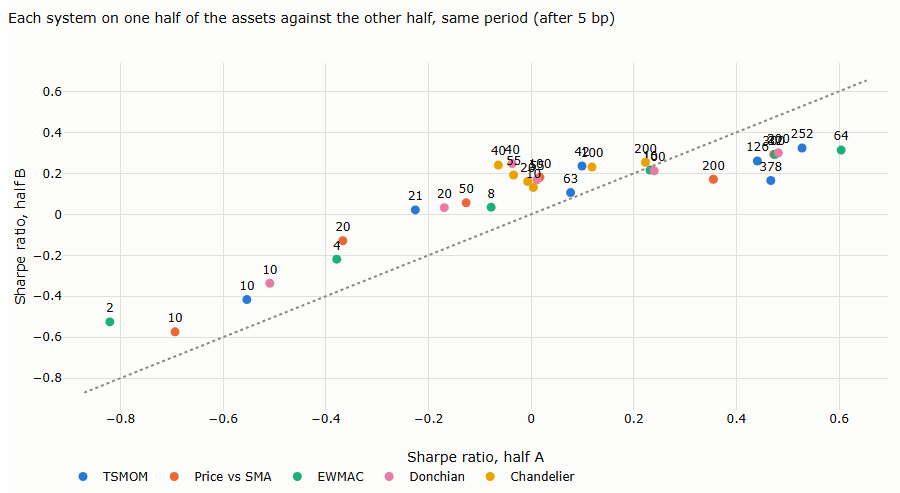

In [18]:
# choose on half of the assets, test on the other half, over the same period: one asset per pair in each half
HALF_A = ["SPY", "EFA", "XLE", "XLF", "XLU", "AGG", "GLD", "GDX"]
HALF_B = ["QQQ", "IWM", "EEM", "XLK", "VNQ", "TLT", "SLV", "USO"]
rows = []
for (f, n), v in V.items():
    na = v["gross_a"][HALF_A].mean(axis=1) - v["to"].mul(0) - (v["pos"][HALF_A].diff().abs().mean(axis=1) * COST)
    nb_ = v["gross_a"][HALF_B].mean(axis=1) - (v["pos"][HALF_B].diff().abs().mean(axis=1) * COST)
    rows.append(dict(family=f, parameter=n, sharpe_A=sharpe(na), sharpe_B=sharpe(nb_)))
TS = pd.DataFrame(rows)
TS["rank_A"] = TS.groupby("family").sharpe_A.rank(); TS["rank_B"] = TS.groupby("family").sharpe_B.rank()
rho = TS.groupby("family").apply(lambda g: g.rank_A.corr(g.rank_B), include_groups=False)
best_A = TS.loc[TS.groupby("family").sharpe_A.idxmax()].set_index("family")
med_B = TS.groupby("family").sharpe_B.median()
display(pd.DataFrame({"rank correlation, half A against half B": rho, "Sharpe on B of the best on A": best_A.sharpe_B,
                      "median Sharpe on B": med_B, "best on B": TS.groupby("family").sharpe_B.max()}).round(2))
print("rank correlation across all 31 systems:", round(TS.sharpe_A.rank().corr(TS.sharpe_B.rank()), 2))
fig = go.Figure()
for fam, g in TS.groupby("family", sort=False):
    fig.add_scatter(x=g.sharpe_A, y=g.sharpe_B, mode="markers+text", text=[str(p) for p in g.parameter], textposition="top center",
                    name=fam, marker=dict(color=FAM_COL[fam], size=9))
lim = [min(TS.sharpe_A.min(), TS.sharpe_B.min()) - 0.05, max(TS.sharpe_A.max(), TS.sharpe_B.max()) + 0.05]
fig.add_scatter(x=lim, y=lim, mode="lines", line=dict(color=MUTED, dash="dot"), showlegend=False)
fig.update_layout(title="Each system on one half of the assets against the other half, same period (after 5 bp)",
                  xaxis_title="Sharpe ratio, half A", yaxis_title="Sharpe ratio, half B", height=520, width=900, margin=dict(t=80),
                  legend=dict(orientation="h", y=-0.15, x=0))
save_figure(fig, "07_10_asset_split", FIG)
fig

## 6. Will it last? (Table 6.1, charts F.11, F.12)

Median against peak per family; walk-forward choice of the parameter (each year, the best on all past data, traded
the next year) against the fixed median parameter and against an equal-weighted blend of all parameters; and the
systems that no other beats on Sharpe ratio, monthly skewness and maximum drawdown at once.

,peak,median across parameters,"walk-forward choice, 2005-2026","fixed middle parameter, 2005-2026","blend of all parameters, 2005-2026"
TSMOM,0.47,0.18,0.46,0.04,0.16
Price vs SMA,0.39,0.02,0.33,0.10,-0.10
EWMAC,0.49,0.11,0.44,0.19,0.00
Donchian,0.42,0.10,0.42,0.08,0.08
Chandelier,0.26,0.09,0.20,0.08,0.12


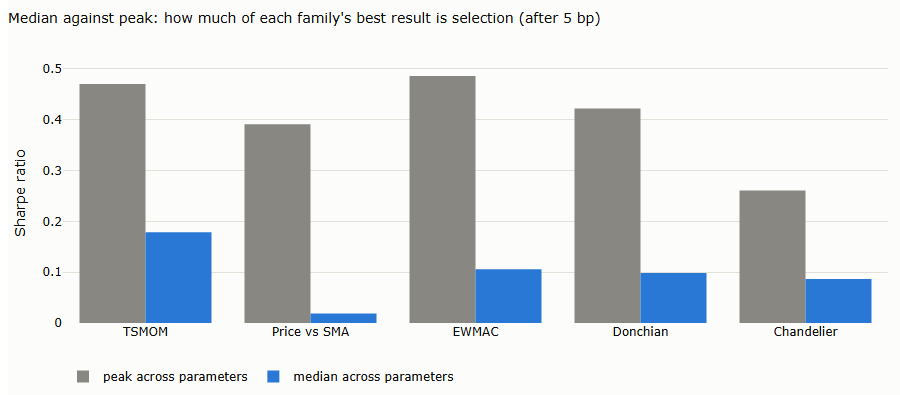

In [19]:
rows = {}
years = range(2005, 2027)
for fam in FAMILIES:
    cols = [k for k in NET.columns if k[0] == fam]
    R = NET[cols]
    wf = []
    for y in years:
        past_ = R.loc[:f"{y - 1}-12-31"]
        best = past_.mean().div(past_.std()).idxmax()
        wf.append(R.loc[str(y), best])
    wf = pd.concat(wf)
    med_k = sorted(cols, key=lambda k: k[1])[len(cols) // 2]
    blend = (R / R.std()).mean(axis=1)
    sl = slice("2005", None)
    rows[fam] = {"peak": max(sharpe(R[c]) for c in cols), "median across parameters": np.median([sharpe(R[c]) for c in cols]),
                 "walk-forward choice, 2005-2026": sharpe(wf), "fixed middle parameter, 2005-2026": sharpe(R[med_k].loc[sl]),
                 "blend of all parameters, 2005-2026": sharpe(blend.loc[sl])}
T61 = pd.DataFrame(rows).T
display(T61.round(2))
fig = go.Figure()
fig.add_bar(x=T61.index, y=T61["peak"], name="peak across parameters", marker_color=MUTED)
fig.add_bar(x=T61.index, y=T61["median across parameters"], name="median across parameters", marker_color=SERIES[0])
fig.update_layout(barmode="group", title="Median against peak: how much of each family's best result is selection (after 5 bp)",
                  yaxis_title="Sharpe ratio", height=420, width=900, margin=dict(t=80), legend=dict(orientation="h", y=-0.15, x=0))
save_figure(fig, "07_11_median_peak", FIG)
display(fig)

,family,parameter,sharpe,skewness,max_dd,undominated
5,TSMOM,252,0.47,0.01,-23.64,True
13,EWMAC,2,-0.72,1.13,-87.46,True
14,EWMAC,4,-0.32,1.11,-62.80,True
15,EWMAC,8,-0.03,1.08,-28.16,True
16,EWMAC,16,0.24,0.77,-22.90,True
17,EWMAC,32,0.41,0.22,-16.55,True
18,EWMAC,64,0.49,-0.09,-18.92,True
24,Donchian,200,0.42,-0.06,-19.45,True
29,Chandelier,100,0.19,1.08,-20.07,True
30,Chandelier,200,0.26,0.47,-16.48,True


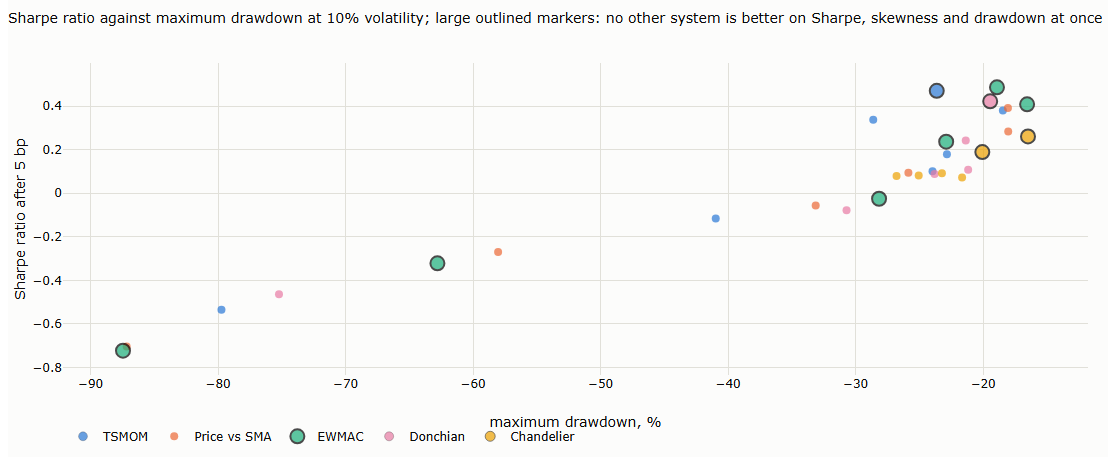

In [20]:
rows = []
for k, v in V.items():
    x = v["net"] / v["net"].std() * TARGET
    m = (1 + x).resample("ME").prod() - 1
    rows.append(dict(family=k[0], parameter=k[1], sharpe=sharpe(x), skewness=m.skew(), max_dd=100 * drawdown(x).min()))
P6 = pd.DataFrame(rows)
def dominated(i):
    a = P6.iloc[i]
    return any((P6.sharpe >= a.sharpe) & (P6.skewness >= a.skewness) & (P6.max_dd >= a.max_dd) &
               ((P6.sharpe > a.sharpe) | (P6.skewness > a.skewness) | (P6.max_dd > a.max_dd)))
P6["undominated"] = [not dominated(i) for i in range(len(P6))]
display(P6[P6.undominated].round(2))
fig = go.Figure()
for fam, g in P6.groupby("family", sort=False):
    fig.add_scatter(x=g.max_dd, y=g.sharpe, mode="markers", name=fam, text=[str(p) for p in g.parameter],
                    marker=dict(color=FAM_COL[fam], size=[14 if u else 8 for u in g.undominated], line=dict(width=[2 if u else 0 for u in g.undominated], color="black")))
fig.update_layout(title="Sharpe ratio against maximum drawdown at 10% volatility; large outlined markers: no other system is better on Sharpe, skewness and drawdown at once",
                  xaxis_title="maximum drawdown, %", yaxis_title="Sharpe ratio after 5 bp", height=480, width=1100, margin=dict(t=80),
                  legend=dict(orientation="h", y=-0.15, x=0))
save_figure(fig, "07_12_tradeoffs", FIG)
fig